<H1> AntennaPatterns </H1> 
Show graphically how two antenna patterns intercept.  
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 30-Oct-25 </td>
        <td> CBL </td> 
        <td> ORIGINAL </td>
    </tr>
    <tr> 
        <td> 31-Oct-25 </td>
        <td> CBL </td> 
        <td> Added in topology </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href="https://newton.i2lab.ucf.edu/wiki/J-pole_antenna"> J-Pole design </a>
<a href="https://www.eznec.com"> EZNEC antenna modeling software</a>
<H2> Notes </H2>

In [1]:
# import packages
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def Pattern(theta):
    """
    @brief - a very simple cos^2 pattern
    @param theta - range of points to produce plot
    @returns 2D pattern
    """
    A1 = np.cos(theta)
    A2 = np.power(A1, 2.0)
    return A2

In [42]:
def Pattern2(x0, y0, Ax, Ay, theta):
    """
    @brief cos2 pattern but with the abilty to change x,y
    @param x0 - offset in x
    @param y0 - offset in y
    @param A  - Amplitude 
    @param theta - number of points to use
    @return X and Y for plot. 
    """
    Amp = np.power(np.cos(theta), 2.0)
    X = Ax*Amp * np.cos(theta) + x0
    Y = Ay*Amp * np.sin(theta) + y0
    return X,Y

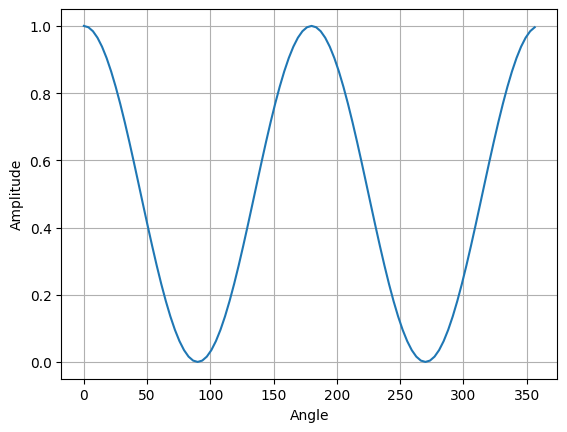

In [18]:
npoints = 100
theta = np.arange(0.0, 2.0*np.pi, 2.0*np.pi/npoints)
#
p0 = Pattern(theta)
#p0 = np.cos(theta)
plt.plot(theta * 180.0/np.pi, p0)
plt.xlabel('Angle')
plt.ylabel('Amplitude')
plt.grid()

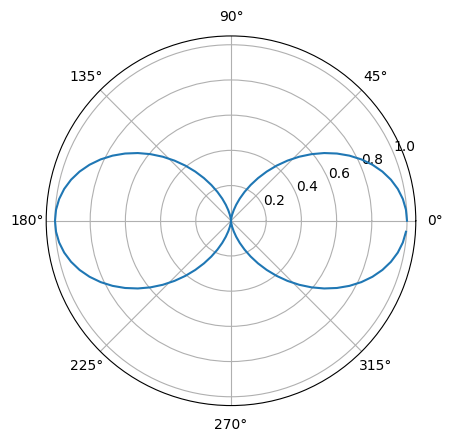

In [19]:
plt.polar(theta,p0)

Text(0, 0.5, 'Altitude in meters')

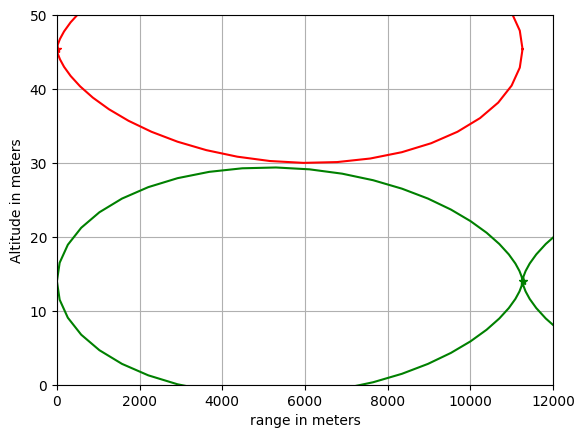

In [50]:
npoints = 100
step = 2 * np.pi/npoints
theta = np.arange(0.0, 2*np.pi+step, step)
"""
transmit pattern, 
in my case there is a a slant range over 11265.4 meters
The altitide at the repeater is 45.4m
The maximum altitude in between is 54.6m
My altitude is 14m

Assume that x is the distance and y is the altitude in the plan that holds the two antennas. 
"""
Distance = 11265.4      # between the two points. 
R_Alt     = 45.4
Ridge_Alt = 54.6
T_Alt     = 14.0
Scale     = 100.0
x0 = 0.0    # Arbitrary offset
y0 = R_Alt
XR,YR = Pattern2(x0,y0,Distance, 40.0, theta)        # repeater
x0 = Distance
y0 = T_Alt
XT,YT = Pattern2(x0,y0, Distance, 40.0, theta)        # transmitter
#
# Plot the positions and altitudes
#
plt.plot(0.0, R_Alt,'r*')        # repeater
plt.plot(Distance, T_Alt, 'g*')  # my location
#
# Put the repeater patter overlaid.
#
plt.plot(XR,YR, 'r')
plt.plot(XT,YT, 'g')
plt.grid()
plt.ylim(0,50)
plt.xlim(0,12000)
plt.xlabel('range in meters')
plt.ylabel('Altitude in meters')